# Tabular Pipeline: Product Recommendation

This notebook cleans and merges the customer social profiles and transactions, explores the merged data, engineers features, and trains a model that predicts which product category a customer will buy. Shared cleaning and feature logic lives in `src/tabular/product_model.py`, so the notebook, the training script and the CLI app all run the same code.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.tabular import product_model as pm

BLUE, ORANGE, MUTED_INK, GRID = "#2a78d6", "#eb6834", "#898781", "#e1e0d9"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
SEQUENTIAL = LinearSegmentedColormap.from_list("blues", ["#f5f9fe", "#86b6ef", "#2a78d6", "#0d366b"])

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
})

social_raw, transactions_raw = pm.load_raw()
print(f"Social profiles: {social_raw.shape}")
print(f"Transactions: {transactions_raw.shape}")

Social profiles: (155, 5)
Transactions: (150, 6)


In [2]:
display(social_raw.head())
display(transactions_raw.head())

,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


## 2. Data cleaning

### Raw data overview

In [3]:
def overview(name: str, df: pd.DataFrame) -> pd.DataFrame:
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns, {df.duplicated().sum()} exact duplicate rows")
    return pd.DataFrame({"dtype": df.dtypes.astype(str), "nulls": df.isna().sum(), "unique": df.nunique()})


display(overview("Social profiles", social_raw))
display(overview("Transactions", transactions_raw))

Social profiles: 155 rows, 5 columns, 5 exact duplicate rows


,dtype,nulls,unique
customer_id_new,str,0,84
social_media_platform,str,0,5
engagement_score,int64,0,50
purchase_interest_score,float64,0,40
review_sentiment,str,0,3


Transactions: 150 rows, 6 columns, 0 exact duplicate rows


,dtype,nulls,unique
customer_id_legacy,int64,0,75
transaction_id,int64,0,150
purchase_amount,int64,0,120
purchase_date,str,0,150
product_category,str,0,5
customer_rating,float64,10,37


In [4]:
duplicates = social_raw[social_raw.duplicated(keep=False)].sort_values("customer_id_new")
display(duplicates)

assert social_raw.duplicated().sum() == 5
assert not transactions_raw.duplicated().any()
assert transactions_raw["transaction_id"].is_unique
assert transactions_raw["customer_rating"].isna().sum() == 10

,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
18,A116,Twitter,78,1.1,Negative
151,A116,Twitter,78,1.1,Negative
73,A125,LinkedIn,66,4.7,Positive
150,A125,LinkedIn,66,4.7,Positive
76,A155,TikTok,98,4.8,Positive
154,A155,TikTok,98,4.8,Positive
78,A162,Twitter,71,4.8,Positive
153,A162,Twitter,71,4.8,Positive
118,A189,Twitter,59,3.8,Neutral
152,A189,Twitter,59,3.8,Neutral


The social file has 5 exact duplicate rows, one extra copy each for customers A116, A125, A155, A162 and A189, so dropping them loses no information. The transactions file has no duplicates and a unique `transaction_id`, but 10 ratings are missing. The two ID columns describe the same customers in different formats (`A178` and `178`), so both files need a shared integer key before any join.

### Cleaning

In [5]:
social = pm.clean_social(social_raw)
transactions = pm.clean_transactions(transactions_raw)

for name, df in [("Social", social), ("Transactions", transactions)]:
    print(f"{name}: {len(df)} rows, {df[pm.KEY].nunique()} customers, ids {df[pm.KEY].min()} to {df[pm.KEY].max()}")
print("Median rating used for the fill:", transactions_raw["customer_rating"].median())
print("Purchase dates:", transactions["purchase_date"].min().date(), "to", transactions["purchase_date"].max().date())

assert len(social) == 150 and not social.duplicated().any()
assert social[pm.KEY].between(100, 199).all() and transactions[pm.KEY].between(100, 199).all()
assert transactions["purchase_date"].dtype.kind == "M"
assert transactions["customer_rating"].notna().all()
assert transactions["rating_missing"].sum() == 10
assert set(social["social_media_platform"]) <= set(pm.ALLOWED_PLATFORMS)
assert set(social["review_sentiment"]) <= set(pm.ALLOWED_SENTIMENTS)
assert set(transactions[pm.TARGET]) == set(pm.ALLOWED_CATEGORIES)

Social: 150 rows, 84 customers, ids 100 to 199
Transactions: 150 rows, 75 customers, ids 100 to 199
Median rating used for the fill: 3.0
Purchase dates: 2024-01-01 to 2024-05-29


Both files now share an integer `customer_id`, the only join key, and the original ID columns are dropped so nobody can join on them by mistake. Missing ratings are flagged in `rating_missing` and then filled with the median, so the model can still tell which ratings were imputed. The median comes from the full file before the train/test split. That is a small leak, accepted because it is a single value computed from 140 observed ratings. Text columns are stripped and mapped to one canonical spelling, and cleaning raises an error on any value outside the allowed lists.

## 3. Merge with validation

### Why not merge directly

In [6]:
for name, df in [("Social", social), ("Transactions", transactions)]:
    rows_per_customer = df.groupby(pm.KEY).size().value_counts().sort_index().to_dict()
    print(f"{name}, customers by number of rows: {rows_per_customer}")

naive_inner = transactions.merge(social, on=pm.KEY, how="inner")
naive_left = transactions.merge(social, on=pm.KEY, how="left")
print(f"Direct inner join: {len(naive_inner)} rows. Direct left join: {len(naive_left)} rows. Transactions: {len(transactions)}.")
assert (len(naive_inner), len(naive_left)) == (213, 246)

Social, customers by number of rows: {1: 43, 2: 23, 3: 13, 4: 4, 6: 1}
Transactions, customers by number of rows: {1: 30, 2: 26, 3: 12, 4: 4, 5: 2, 6: 1}
Direct inner join: 213 rows. Direct left join: 246 rows. Transactions: 150.


Neither file has one row per customer, so a direct join pairs every transaction with every social row for that customer. That inflates 150 transactions to 213 rows (inner) or 246 rows (left), duplicating labels and overweighting customers with many posts. The fix is to aggregate the social table to one row per customer first, which makes the join many-to-one.

### Aggregate social data per customer

In [7]:
def count_ties(column: str) -> int:
    counts = social.groupby(pm.KEY)[column].value_counts()
    is_top = counts == counts.groupby(level=0).transform("max")
    return int((is_top.groupby(level=0).sum() > 1).sum())


social_agg = pm.aggregate_social(social)
assert social_agg[pm.KEY].is_unique and len(social_agg) == social[pm.KEY].nunique()

print(f"{len(social_agg)} customers with social data")
print(f"Customers with a tie for top platform: {count_ties('social_media_platform')}")
print(f"Customers with a tie for top sentiment: {count_ties('review_sentiment')}")
social_agg.head()

84 customers with social data
Customers with a tie for top platform: 25
Customers with a tie for top sentiment: 15


,customer_id,engagement_score,purchase_interest_score,social_post_count,top_platform,top_sentiment
0,100,77.000000,4.400000,2,Instagram,Negative
1,101,68.000000,1.000000,1,Twitter,Neutral
2,102,51.000000,4.800000,1,LinkedIn,Neutral
3,103,64.333333,2.866667,3,Instagram,Positive
4,104,83.000000,2.933333,3,Twitter,Negative


The aggregate keeps the mean `engagement_score` and `purchase_interest_score`, the number of social rows (`social_post_count`), and the most common platform and sentiment. Many customers have only one or two social rows, so ties for the most common value are frequent (25 for platform, 15 for sentiment). Ties are broken alphabetically. That choice is arbitrary but deterministic, so every rerun builds the same dataset.

### Join strategy

The aggregated social table is left joined onto the 150 transactions on `customer_id`, with `validate="many_to_one"` so pandas raises if the social side ever has more than one row per customer. A left join keeps every transaction, because each one carries a target label and the purchases without social data are still valid. An inner join would discard 33 labeled rows (22 percent of a small dataset) and the model would never learn to score customers without a social profile, which the CLI app can meet. `has_social_data` records which rows matched, so the model can treat missing social signal as information.

In [8]:
merged = pm.merge_social(transactions, social_agg)
stats = pm.validate_merge(merged, transactions)

social_ids, transaction_ids = set(social[pm.KEY]), set(transactions[pm.KEY])
shared_customers = len(social_ids & transaction_ids)

print(f"Rows after merge: {stats['rows']}")
print(f"transaction_id unique: {merged['transaction_id'].is_unique}")
print(f"Nulls in key columns: {int(merged[pm.KEY_COLUMNS].isna().sum().sum())}")
print(f"Matched transactions: {stats['matched']}, unmatched: {stats['unmatched']}")
print(f"Customers in both files: {shared_customers}, social only: {len(social_ids - transaction_ids)}, transactions only: {len(transaction_ids - social_ids)}")

assert stats == {"rows": 150, "matched": 117, "unmatched": 33}
assert merged["transaction_id"].is_unique
assert merged[pm.KEY_COLUMNS].notna().all().all()
assert shared_customers == 61
assert merged.loc[merged["has_social_data"], pm.SOCIAL_SCORES].notna().all().all()
assert merged.loc[~merged["has_social_data"], pm.SOCIAL_SCORES].isna().all().all()
pd.testing.assert_frame_equal(merged, pm.load_and_merge())

Rows after merge: 150
transaction_id unique: True
Nulls in key columns: 0
Matched transactions: 117, unmatched: 33
Customers in both files: 61, social only: 23, transactions only: 14


In [9]:
merged.isna().sum().to_frame("nulls").T

,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,customer_id,rating_missing,engagement_score,purchase_interest_score,social_post_count,top_platform,top_sentiment,has_social_data
nulls,0,0,0,0,0,0,0,33,33,0,0,0,0


All checks pass: the merge keeps exactly one row per transaction, 117 transactions matched a social profile and 33 did not, and 61 customers appear in both files. The 23 social-only customers have no purchases and therefore no label, so they cannot be used for training. Unmatched rows get `"Unknown"` for `top_platform` and `top_sentiment` and 0 for `social_post_count`, which are their true values. The two social scores stay empty and are filled inside the model pipeline with a median fitted on training customers only, so the test split never influences the fill. The last assertion confirms that `pm.load_and_merge()`, which the training script uses, produces exactly this table.

## 4. Exploratory data analysis

### Variable types and summary statistics

In [10]:
NUMERIC_EDA = ["purchase_amount", "customer_rating", "engagement_score", "purchase_interest_score", "social_post_count"]

variable_types = pd.DataFrame({
    "dtype": merged.dtypes.astype(str),
    "role": [
        "key" if col in (pm.KEY, "transaction_id")
        else "target" if col == pm.TARGET
        else "datetime" if merged[col].dtype.kind == "M"
        else "boolean" if merged[col].dtype == bool
        else "numeric" if pd.api.types.is_numeric_dtype(merged[col])
        else "categorical"
        for col in merged.columns
    ],
    "unique": merged.nunique(),
})
display(variable_types)
display(merged[NUMERIC_EDA].describe().round(2).T)

,dtype,role,unique
transaction_id,int64,key,150
purchase_amount,int64,numeric,120
purchase_date,datetime64[us],datetime,150
product_category,str,target,5
customer_rating,float64,numeric,37
customer_id,int64,key,75
rating_missing,bool,boolean,2
engagement_score,float64,numeric,44
purchase_interest_score,float64,numeric,46
social_post_count,int64,numeric,5


,count,mean,std,min,25%,50%,75%,max
purchase_amount,150.0,280.78,121.33,51.0,179.00,274.00,388.5,495.0
customer_rating,150.0,2.99,1.17,1.0,2.10,3.00,4.0,5.0
engagement_score,117.0,74.15,12.67,50.0,66.50,77.00,83.0,99.0
purchase_interest_score,117.0,3.08,1.04,1.0,2.67,3.13,3.7,4.8
social_post_count,150.0,1.42,1.09,0.0,1.00,1.00,2.0,4.0


After the merge there are 13 columns: two keys, the target, five numeric columns, two social categoricals, two boolean flags and the purchase date. The social scores have 117 values because the 33 unmatched transactions are left for the pipeline to impute. Purchase amounts run from 51 to 495 with a mean of about 281, and ratings span the full 1 to 5 scale with a mean close to 3.

### Plot 1: target distribution

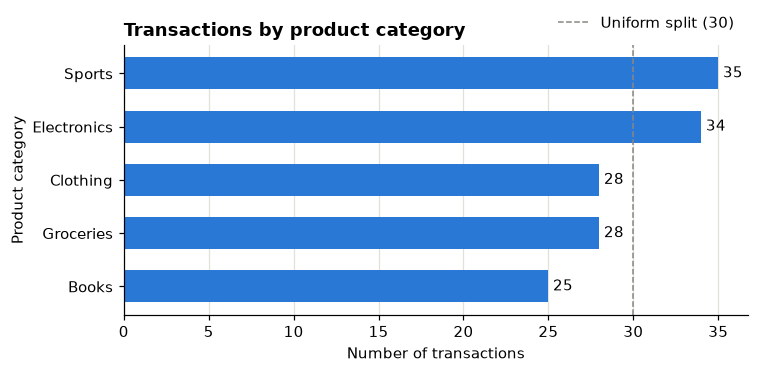

Majority class share: 23.3%


In [11]:
category_counts = merged[pm.TARGET].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(category_counts.index, category_counts.values, color=BLUE, height=0.6)
ax.bar_label(bars, padding=3)
ax.axvline(len(merged) / merged[pm.TARGET].nunique(), color=MUTED_INK, linestyle="--", linewidth=1, label="Uniform split (30)")
ax.set_title("Transactions by product category", loc="left")
ax.set_xlabel("Number of transactions")
ax.set_ylabel("Product category")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", bbox_to_anchor=(1, 1), frameon=False)
plt.tight_layout()
plt.show()

print(f"Majority class share: {category_counts.max() / len(merged):.1%}")

The five classes are close to balanced, from 25 Books to 35 Sports transactions, against 30 each under a uniform split. Random guessing is therefore right about 20 percent of the time, and always predicting Sports would score about 23 percent on the full data. Because no class dominates, macro F1 is a fair headline metric and class weighting is not needed.

### Plot 2: numeric distributions and outliers

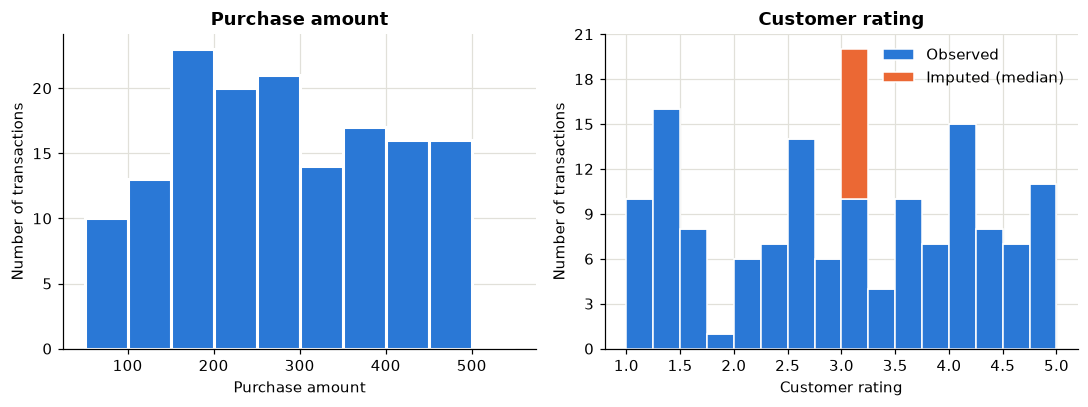

Skew: purchase_amount 0.06, customer_rating -0.08


In [12]:
fig, (ax_amount, ax_rating) = plt.subplots(1, 2, figsize=(10, 3.8))

ax_amount.hist(merged["purchase_amount"], bins=np.arange(50, 551, 50), color=BLUE, edgecolor="white", linewidth=2)
ax_amount.set_title("Purchase amount")
ax_amount.set_xlabel("Purchase amount")
ax_amount.set_ylabel("Number of transactions")

rating_bins = np.arange(1, 5.01, 0.25)
observed = merged.loc[~merged["rating_missing"], "customer_rating"]
imputed = merged.loc[merged["rating_missing"], "customer_rating"]
ax_rating.hist([observed, imputed], bins=rating_bins, stacked=True, color=[BLUE, ORANGE],
               edgecolor="white", linewidth=1, label=["Observed", "Imputed (median)"])
ax_rating.set_title("Customer rating")
ax_rating.set_xlabel("Customer rating")
ax_rating.set_ylabel("Number of transactions")
ax_rating.yaxis.set_major_locator(MaxNLocator(integer=True))
ax_rating.legend(frameon=False)

plt.tight_layout()
plt.show()

print(f"Skew: purchase_amount {merged['purchase_amount'].skew():.2f}, customer_rating {merged['customer_rating'].skew():.2f}")

`purchase_amount` is spread fairly evenly between 51 and 495 with no strong peak and almost no skew, so no log transform is needed. `customer_rating` also covers the full 1 to 5 range. The 10 imputed ratings all sit at the median of 3.0 and create a small artificial spike, which is why `rating_missing` is kept as a feature.

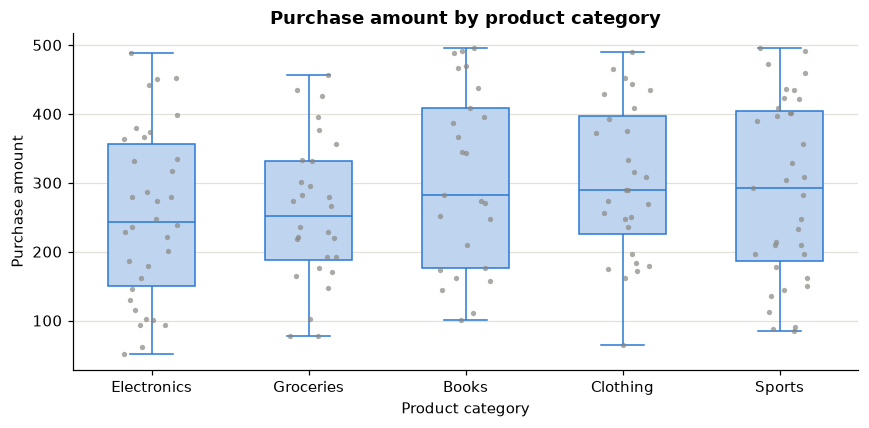

IQR outliers overall: 0
IQR outliers within categories: {'Books': 0, 'Clothing': 0, 'Electronics': 0, 'Groceries': 0, 'Sports': 0}


In [13]:
amount_order = merged.groupby(pm.TARGET)["purchase_amount"].median().sort_values().index

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=merged, x=pm.TARGET, y="purchase_amount", order=amount_order, color="#b7d3f6",
            linecolor=BLUE, width=0.55, fliersize=0, ax=ax)
sns.stripplot(data=merged, x=pm.TARGET, y="purchase_amount", order=amount_order, color=MUTED_INK,
              size=3.5, alpha=0.7, jitter=0.18, ax=ax)
ax.set_title("Purchase amount by product category")
ax.set_xlabel("Product category")
ax.set_ylabel("Purchase amount")
plt.tight_layout()
plt.show()


def iqr_outliers(values: pd.Series) -> int:
    q1, q3 = values.quantile([0.25, 0.75])
    fence = 1.5 * (q3 - q1)
    return int(((values < q1 - fence) | (values > q3 + fence)).sum())


print("IQR outliers overall:", iqr_outliers(merged["purchase_amount"]))
print("IQR outliers within categories:", merged.groupby(pm.TARGET)["purchase_amount"].apply(iqr_outliers).to_dict())

Median purchase amounts range from about 243 (Electronics) to 292 (Sports), and the boxes overlap heavily, so purchase amount alone separates the categories poorly. Electronics and Groceries lean slightly cheaper than the other three, which is the clearest numeric difference in the data. The 1.5 IQR rule finds no outliers in `purchase_amount`, so no capping or removal is applied.

### Plot 3: correlation between numeric features

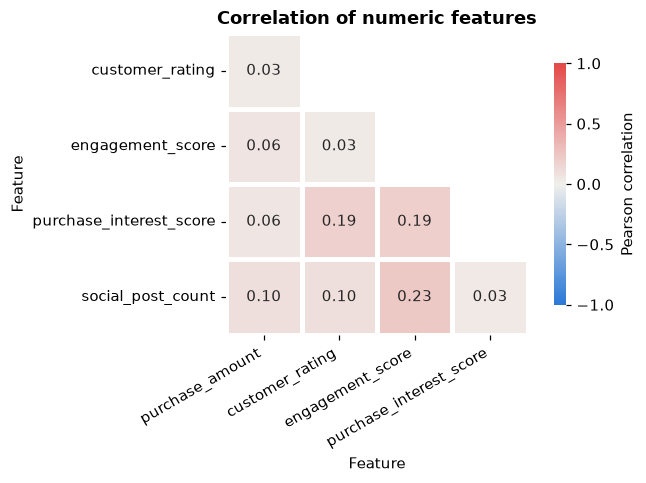

In [14]:
correlations = merged[NUMERIC_EDA].corr().iloc[1:, :-1]
upper_triangle = np.triu(np.ones_like(correlations, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.heatmap(correlations, mask=upper_triangle, annot=True, fmt=".2f", cmap=DIVERGING, vmin=-1, vmax=1,
            center=0, square=True, linewidths=2, linecolor="white", cbar_kws={"label": "Pearson correlation", "shrink": 0.8}, ax=ax)
ax.set_title("Correlation of numeric features")
ax.set_xlabel("Feature")
ax.set_ylabel("Feature")
ax.tick_params(axis="x", rotation=30)
plt.setp(ax.get_xticklabels(), ha="right")
ax.grid(False)
plt.tight_layout()
plt.show()

Every pairwise correlation is weak: the largest are 0.23 (engagement with post count) and 0.19 (purchase interest with both rating and engagement). No pair is close to redundant, so all numeric features are kept without multicollinearity concerns. The pale colors are an honest picture of the data, which contains no strong linear relationships, so model accuracy is expected to be modest.

### Plot 4: social signal by product category

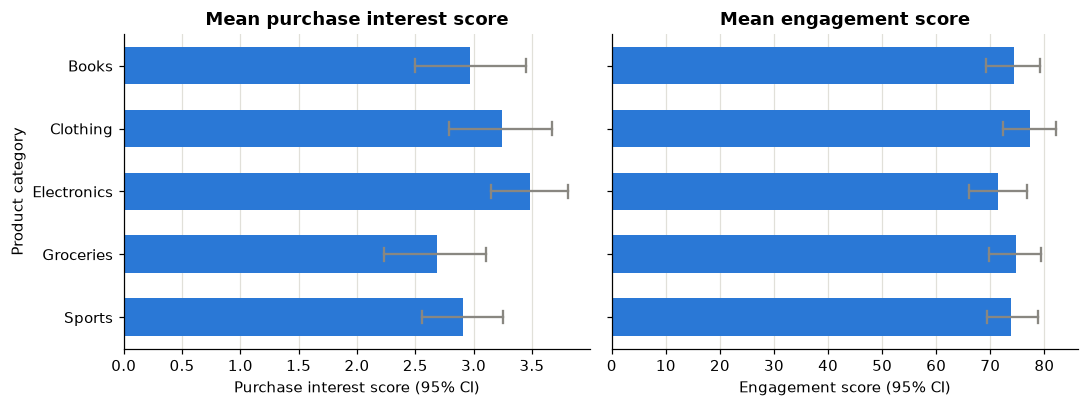

engagement_score       purchase_interest_score      
                             mean count                    mean count
product_category                                                     
Books                       74.31    20                    2.97    20
Clothing                    77.30    22                    3.24    22
Electronics                 71.34    27                    3.49    27
Groceries                   74.72    20                    2.68    20
Sports                      73.88    28                    2.91    28

In [15]:
matched = merged[merged["has_social_data"]]
category_order = sorted(pm.ALLOWED_CATEGORIES)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, column, label in [
    (axes[0], "purchase_interest_score", "Mean purchase interest score"),
    (axes[1], "engagement_score", "Mean engagement score"),
]:
    sns.barplot(data=matched, y=pm.TARGET, x=column, order=category_order, color=BLUE, saturation=1, width=0.6,
                errorbar=("ci", 95), err_kws={"color": MUTED_INK, "linewidth": 1.5}, capsize=0.2, seed=pm.RANDOM_SEED, ax=ax)
    ax.set_title(label)
    ax.set_xlabel(f"{label.removeprefix('Mean ').capitalize()} (95% CI)")
    ax.set_ylabel("Product category")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

matched.groupby(pm.TARGET)[pm.SOCIAL_SCORES].agg(["mean", "count"]).round(2)

Electronics buyers have the highest mean purchase interest (3.49) and Groceries buyers the lowest (2.68), the largest social difference between categories. Their 95 percent intervals only just separate (3.15 versus 3.11), and with ten pairwise comparisons one narrow gap like this could be chance. Engagement means sit between about 71 and 77 with wide, overlapping intervals, so engagement carries little category signal. These means use only the 117 matched transactions, 20 to 28 per category, which is why the intervals are wide.

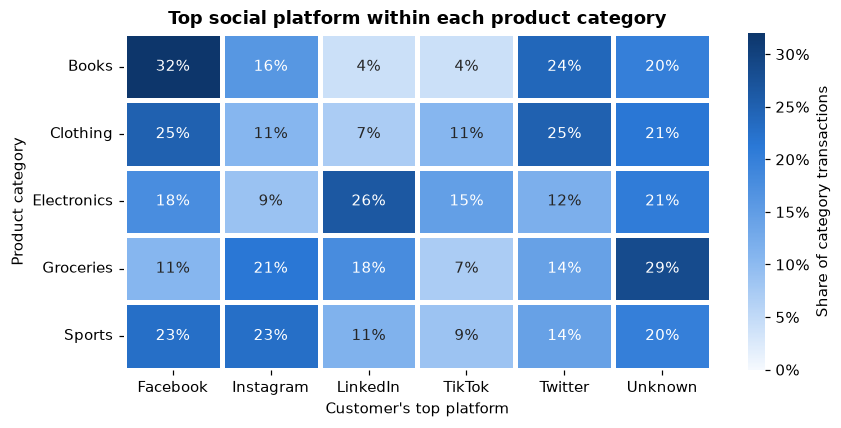

In [16]:
platform_share = pd.crosstab(merged[pm.TARGET], merged["top_platform"], normalize="index")
platform_share = platform_share[pm.ALLOWED_PLATFORMS + [pm.UNKNOWN]]

fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(platform_share, annot=True, fmt=".0%", cmap=SEQUENTIAL, vmin=0, linewidths=2, linecolor="white",
            cbar_kws={"label": "Share of category transactions", "format": "{x:.0%}"}, ax=ax)
ax.set_title("Top social platform within each product category")
ax.set_xlabel("Customer's top platform")
ax.set_ylabel("Product category")
ax.tick_params(axis="y", rotation=0)
ax.grid(False)
plt.tight_layout()
plt.show()

The platform mix differs by category: LinkedIn is the top platform for 26 percent of Electronics transactions but only 4 percent of Books, while Facebook leads for Books at 32 percent. The `Unknown` column shows that 20 to 29 percent of each category has no social data, so missing social data is spread across classes rather than tied to one. Each row rests on only 25 to 35 transactions, so some of these differences are likely noise.